In [1]:
import pprint


import geopandas as gpd
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import contextily
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KernelDensity

from sklearn.metrics import classification_report

import sys
sys.path.append('..')
from model.dataset import LABEL_MAPPING

CLASS_INDICES = [value for key, value in LABEL_MAPPING.items()]
CLASS_NAMES = [key for key in LABEL_MAPPING.keys()]


In [2]:

df = pd.read_csv('../data/labels/dataset_v3/labels.csv')

df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])

gdf = gpd.GeoDataFrame(df)

gdf_train = gdf.loc[gdf.split == 'train']

gdf_val = gdf.loc[gdf.split == 'val']

In [7]:

def tune_bandwidths(gdf_train):

    best_bandwidths = {}


    for _cls in gdf_train.driver.unique():

        df = gdf_train.loc[gdf_train.driver == _cls]

        x = df.geometry.x.values
        y = df.geometry.y.values
        data = np.vstack([x, y]).transpose()


        _min, _max = 0.1, 1

        steps = 5 

        print(_cls)

        for i in range(5):

            params = {
                'bandwidth': np.linspace(_min, _max, steps),
                }  

            grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)  # 5-fold cross-validation
            grid.fit(data)

            # Optimal bandwidth after cross-validation
            best_bandwidth = grid.best_estimator_.bandwidth
            print(best_bandwidth)

            _min, _max = best_bandwidth/5, best_bandwidth*5,
            steps += 5


        best_bandwidths[_cls] = best_bandwidth
        
        
    
    return best_bandwidths
    #print(f"Best bandwidth for class {_cls}: ", best_bandwidth)


In [105]:
#Optimal values I found with grid-search - they do not work well

'''
{'cocoa': 0.048190476190476186,
 'coffee': 1.4906666666666668,
 'forest plantation': 0.1358095238095238,
 'forest regrowth': 0.5910666666666666,
 'mining': 1.4906666666666668,
 'palm oil': 0.1358095238095238,
 'pasture': 0.3365768421052631,
 'rubber': 0.20442907268170427,
 'shifting agriculture': 22.305263157894736,
 'soy': 0.17865323308270675,
 'urban': 9.16842105263158}

'''

"\n{'cocoa': 0.048190476190476186,\n 'coffee': 1.4906666666666668,\n 'forest plantation': 0.1358095238095238,\n 'forest regrowth': 0.5910666666666666,\n 'mining': 1.4906666666666668,\n 'palm oil': 0.1358095238095238,\n 'pasture': 0.3365768421052631,\n 'rubber': 0.20442907268170427,\n 'shifting agriculture': 22.305263157894736,\n 'soy': 0.17865323308270675,\n 'urban': 9.16842105263158}\n\n"

In [42]:
def get_kde_per_class(gdf, bandwidth):
    """
    bandwidth can be either a scalar or a dict with a value for each class
         
    """

    kde_per_class = {}


    for _cls in gdf.driver.unique():

        df = gdf.loc[gdf.driver == _cls]

        x = df.geometry.x.values
        y = df.geometry.y.values
        data = np.vstack([x, y]).transpose()

        if isinstance(bandwidth, dict):
            kde = KernelDensity(kernel='gaussian', bandwidth=bandwidth[_cls]).fit(data)
        else:
            kde = KernelDensity(kernel='gaussian', bandwidth=bandwidth).fit(data)
            
        kde_per_class[_cls] = kde
    
    return kde_per_class


### visualize

In [80]:
#kde_per_class_fixed_bw = get_kde_per_class(gdf_train, 1)
#kde_per_class_scott = get_kde_per_class(gdf_train, 'scott')
kde_per_class_silverman = get_kde_per_class(gdf_train, 'silverman')



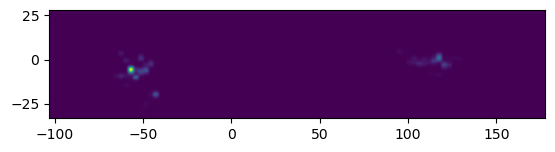

In [68]:

_cls = 'mining'
grid_size= 100


_kde = kde_per_class_fixed_bw[_cls]

xmin = gdf.geometry.x.min()
xmax = gdf.geometry.x.max()
ymin = gdf.geometry.y.min()
ymax = gdf.geometry.y.max()


# Create a grid
xgrid = np.linspace(xmin, xmax, grid_size)
ygrid = np.linspace(ymin, ymax, grid_size)
X, Y = np.meshgrid(xgrid, ygrid)

# Evaluate the KDE on the grid
positions = np.vstack([X.ravel(), Y.ravel()])
positions = np.transpose(positions)

Z = np.reshape(_kde.score_samples(positions).T, X.shape)
Z_exp = np.exp(Z)

# Plot the density
fig, ax = plt.subplots()
ax.imshow(np.flipud(Z_exp), cmap='viridis', extent=[xmin, xmax, ymin, ymax])
ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])
#ax.set_xlabel('X')
#ax.set_ylabel('Y')
#plt.title('2D Gaussian KDE')
plt.show()

## evaluation

- evaluate against having a fixed bandwidth of 1 and then scott and silverman;
- i can easily re-run this when i have more data

In [57]:
classes = gdf.driver.unique()


In [71]:
def evaluate_kdes(kdes, gdf):

    preds = []
    for idx, row in gdf.iterrows():
        kde_in_loc = []
        for _cls in classes:
            point_coords = np.vstack([row.geometry.x, row.geometry.y])
            point_coords = np.transpose(point_coords)


            kde_in_loc.append(kdes[_cls].score_samples(point_coords))


        idx = np.array(kde_in_loc).squeeze().argmax()
        preds.append(classes[idx])
        
    targets = gdf.driver.to_list()

    preds_ind = [LABEL_MAPPING[i] for i in preds]
    targets_ind = [LABEL_MAPPING[i] for i in targets]

    metrics = classification_report(targets_ind, preds_ind, output_dict=True,labels=CLASS_INDICES,target_names=CLASS_NAMES,zero_division=0)

    
    return metrics
    


In [81]:
#metrics_fixed_bw = evaluate_kdes(kde_per_class_fixed_bw, gdf_val)
#metrics_fixed_tuned_bw = evaluate_kdes(kde_per_class, gdf_val)
#metrics_fixed_scott = evaluate_kdes(kde_per_class_scott, gdf_val)
metrics_fixed_silverman = evaluate_kdes(kde_per_class_silverman, gdf_val)

In [76]:
pd.DataFrame(metrics_fixed_bw).T['f1-score'].to_dict()

{'pasture': 0.5664335664335663,
 'forest plantation': 0.30549898167006106,
 'soy': 0.8455433455433455,
 'coffee': 0.09315068493150686,
 'palm oil': 0.6393013100436681,
 'mining': 0.7405512929809606,
 'urban': 0.6036745406824147,
 'cocoa': 0.9988700564971752,
 'rubber': 0.6964155084125823,
 'forest regrowth': 0.48462354188759277,
 'shifting agriculture': 0.8651994497936727,
 'accuracy': 0.6635003362474782,
 'macro avg': 0.6217511162615043,
 'weighted avg': 0.6606387825036445}

In [82]:
pd.DataFrame(metrics_fixed_silverman).T['f1-score'].to_dict()

{'pasture': 0.6436363636363637,
 'forest plantation': 0.4860305745914602,
 'soy': 0.8511569731081926,
 'coffee': 0.10309278350515462,
 'palm oil': 0.591461298160361,
 'mining': 0.7432279909706546,
 'urban': 0.614010343206394,
 'cocoa': 0.9988700564971752,
 'rubber': 0.7486818980667839,
 'forest regrowth': 0.506801399144967,
 'shifting agriculture': 0.9074585635359116,
 'accuracy': 0.687457969065232,
 'macro avg': 0.6540389313112198,
 'weighted avg': 0.6916879760373487}

In [83]:
pd.DataFrame(metrics_fixed_scott).T['f1-score'].to_dict()

{'pasture': 0.6436363636363637,
 'forest plantation': 0.4860305745914602,
 'soy': 0.8511569731081926,
 'coffee': 0.10309278350515462,
 'palm oil': 0.591461298160361,
 'mining': 0.7432279909706546,
 'urban': 0.614010343206394,
 'cocoa': 0.9988700564971752,
 'rubber': 0.7486818980667839,
 'forest regrowth': 0.506801399144967,
 'shifting agriculture': 0.9074585635359116,
 'accuracy': 0.687457969065232,
 'macro avg': 0.6540389313112198,
 'weighted avg': 0.6916879760373487}

In [107]:
pd.DataFrame(metrics_fixed_scott)

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,accuracy,macro avg,weighted avg
precision,0.663543,0.531719,0.835482,0.060241,0.542675,0.845857,0.577365,0.997743,0.790059,0.485480,0.847742,0.687458,0.652537,0.703651
recall,0.624890,0.447573,0.867431,0.357143,0.649886,0.662808,0.655622,1.000000,0.711423,0.530081,0.976226,0.687458,0.680280,0.687458
f1-score,0.643636,0.486031,0.851157,0.103093,0.591461,0.743228,0.614010,0.998870,0.748682,0.506801,0.907459,0.687458,0.654039,0.691688
support,1133.000000,1030.000000,1569.000000,28.000000,1311.000000,1987.000000,996.000000,442.000000,1497.000000,1230.000000,673.000000,0.687458,11896.000000,11896.000000


### Produce a kde.argmax() GeoTiff over the entire study area

In [84]:
xmin, ymin, xmax, ymax = gdf.total_bounds

In [87]:
kde_in_loc = []

# Step 4: Create a grid over which to evaluate the KDE
xmin, ymin, xmax, ymax = gdf.total_bounds
xgrid = np.linspace(xmin, xmax, 1000)  #More longitude than latitude, approx 5x
ygrid = np.linspace(ymin, ymax, 200)
X, Y = np.meshgrid(xgrid, ygrid)
grid_coords = np.vstack([X.ravel(), Y.ravel()])
grid_coords = np.transpose(grid_coords)

for _cls in classes:
    print(_cls)
    # Step 5: Evaluate the KDE on the grid
    #Z = kde(grid_coords).reshape(X.shape)
    kde_in_loc.append(kde_per_class[_cls].score_samples(grid_coords))


#idx = np.array(kde_in_loc).squeeze().argmax()


cocoa
coffee
forest plantation
forest regrowth
mining
palm oil
pasture
rubber
shifting agriculture
soy
urban


In [104]:
for idx, _cls in enumerate(classes):
    print(idx, _cls)

0 cocoa
1 coffee
2 forest plantation
3 forest regrowth
4 mining
5 palm oil
6 pasture
7 rubber
8 shifting agriculture
9 soy
10 urban


In [101]:
grid_coords.shape

(200000, 2)

In [98]:
#cocoa = densities[0]
#pasture = densities[6]
#subset = np.array([cocoa,pasture])

In [100]:
subset.shape

(2, 200000)

In [88]:
densities = np.array(kde_in_loc).squeeze()

In [89]:
densities.argmax(axis=0).reshape(X.shape).shape

(200, 1000)

In [90]:
most_likely_cls = densities.argmax(axis=0).reshape(X.shape)

In [102]:
most_likely_cls = np.flipud(most_likely_cls)

In [103]:
import rasterio
from rasterio.transform import from_bounds
import numpy as np

# Define the bounding box (left, bottom, right, top) and the array
array = most_likely_cls.astype('int8')  
output_filepath = '../data/tmp/kde_2.tif'

# Number of rows and columns in your array
rows, cols = array.shape

# Define the transform based on the bounding box and array dimensions
transform = from_bounds(xmin, ymin, xmax, ymax, cols, rows)

# Define the metadata
metadata = {
    'driver': 'GTiff',  # GeoTIFF
    'height': rows,
    'width': cols,
    'count': 1,  # Number of bands
    'dtype': str(array.dtype),
    'crs': '+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs',  # WGS84 Coordinate Reference System
    'transform': transform
}

# Write the dataset
with rasterio.open(output_filepath, 'w', **metadata) as dst:
    dst.write(array, 1)  # Writing the array data to the first band